# ⚛️ Wprowadzenie do obliczeń kwantowych
## 🧮 Laboratorium 3 - obwody kwantowe
**Katedra Informatyki, Mechaniki i Robotyki | wersja 0.2**

Notebook zawiera treści zadań, opisy przydatnych metod i funkcje pomocnicze oraz miejsca na samodzielne rozwiązania analityczne i ich numeryczną weryfikację w Pythonie i Qiskicie.


## 🔑 Karta referencyjna (notacja Diraca ↔ Qiskit)

| Operacja | Zapis matematyczny | Qiskit / NumPy | Uwaga |
|---|---|---|---|
| Wektor stanu | $|\psi\rangle=\alpha|0\rangle+\beta|1\rangle$ | `Statevector([alpha, beta])` | Musi zachodzić $|\alpha|^2+|\beta|^2=1$ |
| Prawdopodobieństwa | $p_k=|\langle k|\psi\rangle|^2$ | `state.probabilities_dict()` | Dotyczą pomiaru w bazie obliczeniowej |
| Ewolucja podanego stanu | $|\psi'\rangle=U|\psi\rangle$ | `state.evolve(qc)` | Obwód działa na stan zapisany w `state` |
| Ewolucja od stanu zerowego | $|\psi'\rangle=U|0\ldots0\rangle$ | `Statevector.from_instruction(qc)` | Wszystkie kubity początkowo są w stanie $|0\rangle$ |
| Operator | macierz $U$ | `Operator(gate)` | `operator.is_unitary()` sprawdza unitarność |
| Iloczyn tensorowy | $|q_1\rangle\otimes|q_0\rangle$ | `np.kron(q1, q0)` | Qiskit zapisuje bazę jako $|q_{n-1}\ldots q_0\rangle$ |
| Równość z fazą globalną | $|\phi\rangle=e^{i\gamma}|\psi\rangle$ | `state1.equiv(state2)` | Faza globalna nie zmienia stanu fizycznego |


## 💡 Wskazówki do rozwiązywania zadań

1. Najpierw wykonaj obliczenia na wektorach i macierzach, a następnie porównaj je z wynikiem Qiskita.
2. W zapisie macierzowym bramka wykonana jako pierwsza znajduje się najbliżej wektora: „najpierw $U_1$, potem $U_2$” oznacza $U_2U_1|\psi\rangle$.
3. Qiskit stosuje konwencję little-endian: dla dwóch kubitów etykieta ma postać $|q_1q_0\rangle$.
4. Wektory stanu porównuj metodą `equiv`, jeżeli dopuszczasz nieistotną fizycznie fazę globalną.
5. Liczby zmiennoprzecinkowe porównuj za pomocą `np.isclose` lub `np.allclose`, a nie operatorem `==`.
6. Faza względna nie zmienia prawdopodobieństw bezpośredniego pomiaru w bazie obliczeniowej, ale wpływa na interferencję i wyniki pomiarów w innych bazach.

### Uruchomienie notebooka i sposób pracy

1. Uruchom poniższą komórkę sprawdzającą wymagane pakiety. Instalacja brakujących pakietów wymaga dostępu do internetu.
2. Jeśli zainstalowano pakiety, uruchom ponownie kernel z menu Jupytera. Następnie uruchom komórkę importów i definicji funkcji pomocniczych.
3. Wykonaj przykłady użycia funkcji pomocniczych.
4. Dla każdego zadania najpierw uzupełnij komórkę Markdown **„Obliczenia i uzasadnienie”**, a następnie komórkę Code **„Weryfikacja i porównanie wyników”**.
5. W części analitycznej pokaż tok obliczeń. W części Python porównaj otrzymany wynik z przewidywaniem analitycznym, np. przez `np.isclose`, `np.allclose` lub `equiv`.

Przykłady w karcie metod są podpowiedziami. Nie zastępują uzasadnienia rozwiązania zadania.


In [1]:
import importlib.util
import subprocess
import sys

# Nazwa importu -> nazwa pakietu instalowanego przez pip
required_packages = {
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "qiskit": "qiskit",
    "pylatexenc": "pylatexenc",  # Wsparcie rysowania obwodów przez qc.draw("mpl")
}

installed_now = []
for import_name, package_name in required_packages.items():
    if importlib.util.find_spec(import_name) is None:
        print(f"Brak pakietu '{package_name}'. Instalacja...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package_name])
        installed_now.append(package_name)
    else:
        print(f"Pakiet '{package_name}' jest już zainstalowany.")

if installed_now:
    print("\nZainstalowano: " + ", ".join(installed_now))
    print("Uruchom ponownie kernel z menu Jupytera, a potem komórkę funkcji pomocniczych.")
else:
    print("\nWszystkie wymagane pakiety są gotowe. Możesz uruchomić komórkę funkcji pomocniczych.")


Pakiet 'numpy' jest już zainstalowany.
Pakiet 'matplotlib' jest już zainstalowany.
Pakiet 'qiskit' jest już zainstalowany.
Pakiet 'pylatexenc' jest już zainstalowany.

Wszystkie wymagane pakiety są gotowe. Możesz uruchomić komórkę funkcji pomocniczych.


### Funkcje pomocnicze

Uruchom poniższą komórkę raz po uruchomieniu lub restarcie kernela. Zawiera ona importy oraz trzy funkcje:

| Funkcja | Działanie | Zwracany wynik |
|:---|:---|:---|
| `show_probabilities(sv, digits=3)` | Wyświetla tabelę prawdopodobieństw pomiaru w bazie obliczeniowej; `digits` określa liczbę miejsc po przecinku | Brak (`None`) |
| `project_on_outcome(sv, outcome)` | Oblicza prawdopodobieństwo wskazanego wyniku i znormalizowany stan warunkowy | Para `(probability, state_after)` |
| `show_projection(sv, outcome)` | Wykonuje te same obliczenia i dodatkowo wyświetla prawdopodobieństwo oraz stan | Para `(probability, state_after)` |

Argument `sv` musi opisywać poprawnie znormalizowany stan kubitów. `outcome` jest ciągiem bitów, np. `"1"` dla jednego kubitu lub `"01"` dla dwóch kubitów, w konwencji Qiskita.

**Funkcje nie losują wyniku pomiaru i nie zmieniają wejściowego stanu.** Rzutowanie dotyczy pomiaru wszystkich kubitów w bazie obliczeniowej, przy założeniu wskazanego wyniku. Dla wyniku o zerowym prawdopodobieństwie stan warunkowy nie jest określony — funkcja zgłasza wtedy błąd.

Tabela prawdopodobieństw może pomijać stany o zerowym prawdopodobieństwie. Do ich sprawdzania używaj `sv.probabilities_dict().get("01", 0.0)`, podając właściwą etykietę stanu.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from IPython.display import display, Markdown
from qiskit import QuantumCircuit
from qiskit.circuit.library import HGate, XGate, YGate, ZGate, SGate, TGate, CXGate
from qiskit.quantum_info import Operator, Statevector
from qiskit.visualization import plot_bloch_multivector

def show_probabilities(sv, digits=3):
    """Wyświetla prawdopodobieństwa pomiaru w bazie obliczeniowej."""
    if not sv.is_valid():
        raise ValueError("Stan wejściowy musi być znormalizowany.")

    rows = [
        "| Stan | Prawdopodobieństwo | Procent |",
        "|:---:|---:|---:|",
    ]

    for state, probability in sv.probabilities_dict().items():
        rows.append(
            f"| $\\vert {state}\\rangle$ "
            f"| {probability:.{digits}f} "
            f"| {100 * probability:.1f}% |"
        )

    display(Markdown("\n".join(rows)))

def project_on_outcome(sv, outcome):
    """Zwraca prawdopodobieństwo wyniku i stan po pomiarze.

    Dotyczy pomiaru wszystkich kubitów w bazie obliczeniowej.
    outcome: ciąg bitów, np. "1" lub "01", w konwencji Qiskit.
    """
    if not sv.is_valid():
        raise ValueError("Stan wejściowy musi być znormalizowany.")

    if sv.num_qubits is None:
        raise ValueError("Funkcja obsługuje wyłącznie stany kubitów.")

    if (
        not isinstance(outcome, str)
        or len(outcome) != sv.num_qubits
        or any(bit not in "01" for bit in outcome)
    ):
        raise ValueError("Podaj po jednym bicie 0 lub 1 na każdy kubit.")

    index = int(outcome, 2)
    probability = float(sv.probabilities()[index])

    if probability == 0:
        raise ValueError("Ten wynik ma zerowe prawdopodobieństwo.")

    # Rzutowanie: pozostawiamy tylko amplitudę wybranego wyniku.
    projected = np.zeros_like(sv.data)
    projected[index] = sv.data[index]

    # Normalizacja stanu po rzutowaniu.
    state_after = Statevector(projected / np.sqrt(probability))

    return probability, state_after

def show_projection(sv, outcome):
    """Wyświetla prawdopodobieństwo wyniku i warunkowy stan po pomiarze."""
    probability, state_after = project_on_outcome(sv, outcome)

    display(Markdown(
        f"**Założony wynik pomiaru: `{outcome}`**\n\n"
        f"Prawdopodobieństwo tego wyniku: **{probability:.3f}** "
        f"(**{100 * probability:.1f}%**).\n\n"
        "Stan po pomiarze:"
    ))
    display(state_after.draw("latex"))

    return probability, state_after    
    

print(f"✅ Załadowano funkcje pomocnicze. Qiskit {qiskit.__version__}")


✅ Załadowano funkcje pomocnicze. Qiskit 2.6.1


# Przykład użycia funkcji pomocniczych


In [3]:
from qiskit.quantum_info import Statevector

sv =  Statevector([0.8, 0.6])
show_probabilities(sv)

| Stan | Prawdopodobieństwo | Procent |
|:---:|---:|---:|
| $\vert 0\rangle$ | 0.640 | 64.0% |
| $\vert 1\rangle$ | 0.360 | 36.0% |

In [4]:
# Dwa niezależne rzutowania tego samego stanu wejściowego sv.
# Nie są to kolejne pomiary jednego układu.
p0, state_after_0 = show_projection(sv, "0")
p1, state_after_1 = show_projection(sv, "1")


**Założony wynik pomiaru: `0`**

Prawdopodobieństwo tego wyniku: **0.640** (**64.0%**).

Stan po pomiarze:

<IPython.core.display.Latex object>

**Założony wynik pomiaru: `1`**

Prawdopodobieństwo tego wyniku: **0.360** (**36.0%**).

Stan po pomiarze:

<IPython.core.display.Latex object>

## Przydatne klasy i metody Qiskit

W zadaniach korzystamy z trzech sposobów opisywania obliczeń:

- `QuantumCircuit` — opis obwodu, czyli kubitów i wykonywanych operacji;
- `Statevector` — wektor opisujący konkretny czysty stan kwantowy;
- `Operator` — operator opisujący działanie bramki lub całego obwodu.

### 1. `QuantumCircuit` — tworzenie obwodu

```python
from qiskit import QuantumCircuit

qc = QuantumCircuit(1)
qc.x(0)
qc.h(0)
```

`QuantumCircuit(1)` tworzy obwód z jednym kubitem. Metody `x(0)` i `h(0)`
dodają odpowiednio bramki X i H działające na kubicie o indeksie `0`.

Bramki w kodzie zapisujemy w kolejności ich wykonywania:
najpierw X, następnie H. Działanie na stan zapisujemy jako:
$$
|\psi_{\mathrm{końcowy}}\rangle
=H\bigl(X|\psi\rangle\bigr)
=(HX)|\psi\rangle.
$$

Najpierw obliczamy $X|\psi\rangle$, a następnie do otrzymanego
stanu stosujemy H. Dlatego operatorem całkowitym jest $HX$ —
operator stojący najbardziej po prawej działa jako pierwszy.

Samo utworzenie obwodu i dodanie bramek nie uruchamia symulacji.

### 2. `Statevector([alpha, beta])` — stan z podanych amplitud

```python
from qiskit.quantum_info import Statevector

sv = Statevector([alpha, beta])
```

Konstruktor tworzy obiekt opisujący stan:
$$
|\psi\rangle=\alpha|0\rangle+\beta|1\rangle.
$$

Kolejność elementów listy odpowiada kolejności stanów bazowych:

- pierwszy element — amplituda przy $|0\rangle$;
- drugi element — amplituda przy $|1\rangle$.

Podajemy **amplitudy**, a nie prawdopodobieństwa. Mogą one być liczbami
zespolonymi.

Przykład:

```python
sv = Statevector([2 / np.sqrt(5), 1j / np.sqrt(5)])
```

Opisuje on stan:
$$
|\psi\rangle=\frac{2}{\sqrt5}|0\rangle+\frac{i}{\sqrt5}|1\rangle.
$$

Konstruktor nie normalizuje automatycznie podanego wektora.
Poprawność normalizacji możemy sprawdzić za pomocą:

```python
sv.is_valid()
```

### 3. `Statevector.from_instruction(qc)` — stan wynikający z obwodu

```python
sv = Statevector.from_instruction(qc)
```

Metoda oblicza stan otrzymany po zastosowaniu operacji z obwodu `qc`,
zakładając, że wszystkie kubity początkowo znajdują się w stanie
$|0\rangle$.

Dla jednego kubitu:
$$
|\psi_{\mathrm{końcowy}}\rangle=U|0\rangle,
$$
gdzie $U$ jest operatorem obwodu.

Dla przykładu z bramkami X, następnie H:
$$
|\psi_{\mathrm{końcowy}}\rangle
=HX|0\rangle=|-\rangle.
$$

**Uwaga:** wywołanie nie korzysta z wcześniej utworzonego obiektu `sv`.
Jeżeli chcemy zastosować obwód do własnego stanu początkowego,
używamy:

```python
sv_initial = Statevector([alpha, beta])
sv_final = sv_initial.evolve(qc)
```

Wtedy obliczamy $U|\psi_{\mathrm{initial}}\rangle$, zamiast $U|0\rangle$.

W omawianych przykładach przekazujemy obwody bez instrukcji pomiaru.

### 4. `sv.data` — dostęp do amplitud

```python
sv.data
```

Atrybut `data` udostępnia amplitudy jako tablicę NumPy. Dla jednego kubitu:

```python
alpha = sv.data[0]
beta = sv.data[1]
```

Prawdopodobieństwo uzyskujemy przez obliczenie kwadratu modułu amplitudy:

```python
p1 = abs(sv.data[1]) ** 2
```

### 5. `sv.probabilities_dict()` — prawdopodobieństwa pomiaru

```python
probabilities = sv.probabilities_dict()
```

Metoda zwraca słownik z prawdopodobieństwami pomiaru w bazie obliczeniowej.
Kluczami są ciągi bitów opisujące stany bazowe, a wartościami —
ich prawdopodobieństwa.

Przykładowy wynik:

```python
{"0": 0.8, "1": 0.2}
```

Odczyt prawdopodobieństwa wyniku 1:

```python
p1 = probabilities.get("1", 0.0)
```

Użycie `.get("1", 0.0)` zapewnia wynik `0.0`, jeżeli klucz `"1"`
został pominięty z powodu zerowego prawdopodobieństwa.

Metoda oblicza:
$$
P(0)=|\alpha|^2,
\qquad
P(1)=|\beta|^2.
$$

**Nie losuje wyniku pomiaru i nie zmienia stanu.**
Słownik prawdopodobieństw nie zawiera pełnej informacji o fazach amplitud.

### 6. `Operator(qc).data` — macierz całego obwodu

```python
from qiskit.quantum_info import Operator

matrix = Operator(qc).data
```

`Operator(qc)` tworzy reprezentację operatora obwodu, a `.data`
udostępnia jego macierz jako tablicę NumPy.

Dla obwodu z jednym kubitem jest to macierz $2\times2$.
Dla obwodu z $n$ kubitami ma ona rozmiar $2^n\times2^n$.

Jeżeli obwód `qc_hx` zawiera najpierw H, a następnie X:

```python
qc_hx = QuantumCircuit(1)
qc_hx.h(0)
qc_hx.x(0)

matrix = Operator(qc_hx).data
```

otrzymujemy:
$$
U=XH.
$$

Operator opisuje działanie obwodu na **dowolny stan wejściowy**,
natomiast `Statevector.from_instruction(qc_hx)` daje konkretny wynik
dla wejścia $|0\rangle$.

Ta metoda jest odpowiednia dla omawianych obwodów złożonych z bramek
unitarnych, bez pomiarów.

### 7. `sv.draw("latex")` — wyświetlanie stanu

```python
display(sv.draw("latex"))
```

Przedstawia stan w zapisie matematycznym, np.:
$$
\frac{|0\rangle-|1\rangle}{\sqrt2}.
$$

Do wyświetlania macierzy możemy użyć:

```python
from qiskit.visualization import array_to_latex

display(array_to_latex(matrix))
```

Obie funkcje służą do prezentacji wyników i nie zmieniają stanu ani operatora.

### 8. Porównywanie wyników

Do porównywania macierzy i liczb zmiennoprzecinkowych używamy:

```python
np.allclose(matrix_a, matrix_b)
np.isclose(p1, 0.5)
```

Funkcje dopuszczają niewielkie różnice wynikające z dokładności obliczeń
numerycznych. Zwracają wartość logiczną.

Stany fizyczne możemy porównywać za pomocą:

```python
sv_a.equiv(sv_b)
```

Metoda `equiv` uwzględnia równoważność z dokładnością do fazy globalnej.
Na przykład $|1\rangle$ oraz $i|1\rangle$ opisują ten sam stan fizyczny.

### Zestawienie

| Zapis | Zastosowanie |
|:---|:---|
| `QuantumCircuit(1)` | Utworzenie obwodu jednokubitowego |
| `qc.x(0)`, `qc.h(0)` | Dodanie bramek do obwodu |
| `Statevector([alpha, beta])` | Utworzenie stanu z amplitud |
| `Statevector.from_instruction(qc)` | Obliczenie stanu z obwodu dla początkowych zer |
| `sv.evolve(qc)` | Zastosowanie obwodu do podanego stanu |
| `sv.data` | Dostęp do amplitud |
| `sv.probabilities_dict()` | Obliczenie prawdopodobieństw pomiaru |
| `Operator(qc).data` | Uzyskanie macierzy operatora obwodu |
| `sv.draw("latex")` | Wyświetlenie stanu |
| `sv.equiv(other)` | Porównanie stanów z pominięciem fazy globalnej |


# ✍️ Zadania


## 🧩 Zadanie 1: Normalizacja, faza i redukcja stanu

Dany jest stan
$$|\psi\rangle=\alpha|0\rangle+\beta|1\rangle,$$
gdzie $\alpha=\frac{2}{\sqrt5}$ oraz $\beta=xe^{i\phi}$, $x>0$, $\phi=\frac\pi2$.

1. Wyznacz $x$ z warunku normalizacji i zapisz jawny wektor stanu.
2. Oblicz prawdopodobieństwa wyników 0 i 1. Omów rolę fazy.
3. Podaj stan po pomiarze, jeśli otrzymano wynik 1.
4. Zweryfikuj normalizację i prawdopodobieństwa za pomocą `Statevector` i `probabilities_dict()`. Stan warunkowy z punktu 3 możesz sprawdzić funkcją `project_on_outcome` lub `show_projection`. Omówienie roli fazy umieść w części analitycznej.


#### ✍️ Obliczenia i uzasadnienie

**1. Normalizacja.** Musi zachodzić $|\alpha|^2+|\beta|^2=1$, przy czym $|\beta|^2=x^2\,|e^{i\phi}|^2=x^2$:
$$\frac45+x^2=1\;\Rightarrow\;x^2=\frac15\;\Rightarrow\;x=\frac1{\sqrt5}\quad(x>0).$$
Dla $\phi=\frac\pi2$ mamy $e^{i\pi/2}=i$, więc $\beta=\frac{i}{\sqrt5}$ oraz
$$|\psi\rangle=\frac{2}{\sqrt5}|0\rangle+\frac{i}{\sqrt5}|1\rangle=\frac1{\sqrt5}\begin{pmatrix}2\\ i\end{pmatrix}.$$

**2. Prawdopodobieństwa.**
$$p(0)=|\alpha|^2=\frac45=0{,}8,\qquad p(1)=|\beta|^2=\left|\frac{i}{\sqrt5}\right|^2=\frac15=0{,}2,\qquad p(0)+p(1)=1.$$

**Rola fazy.** Ponieważ $|e^{i\phi}|=1$, faza $\phi$ nie wpływa na prawdopodobieństwa pomiaru w bazie obliczeniowej — dla każdego $\phi$ otrzymamy $0{,}8$ i $0{,}2$. Jest to jednak faza **względna** (między amplitudami przy $|0\rangle$ i $|1\rangle$), więc zmienia stan fizyczny. Wektor Blocha ma składowe
$$r_x=2\,\mathrm{Re}(\alpha^*\beta)=0,\qquad r_y=2\,\mathrm{Im}(\alpha^*\beta)=\frac45,\qquad r_z=|\alpha|^2-|\beta|^2=\frac35,$$
a dla $\phi=0$ byłoby $r_x=\frac45,\ r_y=0$ — faza obraca wektor wokół osi $z$. Różnicę widać w pomiarze w innej bazie, np. $\{|+\rangle,|-\rangle\}$:
$$p(+)=|\langle+|\psi\rangle|^2=\left|\frac{2+i}{\sqrt{10}}\right|^2=\frac12,$$
podczas gdy dla $\phi=0$: $p(+)=\left(\frac{3}{\sqrt{10}}\right)^2=0{,}9$.

**3. Stan po pomiarze z wynikiem 1.** Rzutujemy na $|1\rangle$ i normalizujemy:
$$|\psi'\rangle=\frac{|1\rangle\langle1|\psi\rangle}{\sqrt{p(1)}}=\frac{i/\sqrt5}{1/\sqrt5}\,|1\rangle=i|1\rangle.$$
Czynnik $i$ jest fazą globalną, więc fizycznie stan po pomiarze to $|1\rangle$.


In [5]:
alpha = 2 / np.sqrt(5)
x = np.sqrt(1 - alpha ** 2)
beta = x * np.exp(1j * np.pi / 2)
psi = Statevector([alpha, beta])

print(f"x = {x:.6f}, 1/sqrt(5) = {1 / np.sqrt(5):.6f}, zgodność: {np.isclose(x, 1 / np.sqrt(5))}")
print("Wektor zgodny z (2, i)/sqrt(5):", np.allclose(psi.data, np.array([2, 1j]) / np.sqrt(5)))
print("Normalizacja:", psi.is_valid())
display(psi.draw("latex"))

probabilities = psi.probabilities_dict()
p0 = probabilities.get("0", 0.0)
p1 = probabilities.get("1", 0.0)
print(f"p(0) = {p0:.3f}, zgodność z 4/5: {np.isclose(p0, 4 / 5)}")
print(f"p(1) = {p1:.3f}, zgodność z 1/5: {np.isclose(p1, 1 / 5)}")
show_probabilities(psi)

p1_proj, psi_after = show_projection(psi, "1")
print("Stan po pomiarze = i|1>:", np.allclose(psi_after.data, [0, 1j]))
print("Stan po pomiarze równoważny |1>:", psi_after.equiv(Statevector([0, 1])))

psi_phase0 = Statevector([alpha, x])
qc_h = QuantumCircuit(1)
qc_h.h(0)
print("Te same p(0), p(1) dla phi = 0 i phi = pi/2:", np.allclose(psi.probabilities(), psi_phase0.probabilities()))
print(f"p(+) dla phi = pi/2: {psi.evolve(qc_h).probabilities()[0]:.3f}, oczekiwane 0.5")
print(f"p(+) dla phi = 0:    {psi_phase0.evolve(qc_h).probabilities()[0]:.3f}, oczekiwane 0.9")

x = 0.447214, 1/sqrt(5) = 0.447214, zgodność: True
Wektor zgodny z (2, i)/sqrt(5): True
Normalizacja: True


<IPython.core.display.Latex object>

p(0) = 0.800, zgodność z 4/5: True
p(1) = 0.200, zgodność z 1/5: True


| Stan | Prawdopodobieństwo | Procent |
|:---:|---:|---:|
| $\vert 0\rangle$ | 0.800 | 80.0% |
| $\vert 1\rangle$ | 0.200 | 20.0% |

**Założony wynik pomiaru: `1`**

Prawdopodobieństwo tego wyniku: **0.200** (**20.0%**).

Stan po pomiarze:

<IPython.core.display.Latex object>

Stan po pomiarze = i|1>: True
Stan po pomiarze równoważny |1>: True
Te same p(0), p(1) dla phi = 0 i phi = pi/2: True
p(+) dla phi = pi/2: 0.500, oczekiwane 0.5
p(+) dla phi = 0:    0.900, oczekiwane 0.9


## 🧩 Zadanie 2: Ewolucja stanu i kolejność operacji

Dla stanu początkowego $|\psi_0\rangle=|0\rangle$ zastosuj najpierw $X$, a następnie $H$.

1. Wyznacz stan pośredni i końcowy.
2. Zapisz operator całkowity i zweryfikuj obwód w Qiskicie.
3. Odwróć kolejność bramek. Sprawdź przemienność i porównaj prawdopodobieństwo wyniku 1.


#### ✍️ Obliczenia i uzasadnienie

**1. Stan pośredni i końcowy.**
$$|\psi_1\rangle=X|0\rangle=\begin{pmatrix}0&1\\1&0\end{pmatrix}\begin{pmatrix}1\\0\end{pmatrix}=\begin{pmatrix}0\\1\end{pmatrix}=|1\rangle,$$
$$|\psi_2\rangle=H|1\rangle=\frac1{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}\begin{pmatrix}0\\1\end{pmatrix}=\frac1{\sqrt2}\begin{pmatrix}1\\-1\end{pmatrix}=|-\rangle.$$

**2. Operator całkowity.** Najpierw $X$, potem $H$, więc $U=HX$:
$$U=HX=\frac1{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}\begin{pmatrix}0&1\\1&0\end{pmatrix}=\frac1{\sqrt2}\begin{pmatrix}1&1\\-1&1\end{pmatrix},\qquad U|0\rangle=\frac1{\sqrt2}\begin{pmatrix}1\\-1\end{pmatrix}=|-\rangle.$$

**3. Odwrócona kolejność.** Najpierw $H$, potem $X$, więc $U'=XH$:
$$U'=XH=\frac1{\sqrt2}\begin{pmatrix}0&1\\1&0\end{pmatrix}\begin{pmatrix}1&1\\1&-1\end{pmatrix}=\frac1{\sqrt2}\begin{pmatrix}1&-1\\1&1\end{pmatrix},\qquad U'|0\rangle=X|+\rangle=|+\rangle.$$

Bramki nie są przemienne:
$$[H,X]=HX-XH=\frac1{\sqrt2}\begin{pmatrix}0&2\\-2&0\end{pmatrix}\neq0.$$
Nie jest to też różnica fazy globalnej: $HX(XH)^{-1}=(HX)^2=\begin{pmatrix}0&1\\-1&0\end{pmatrix}\neq e^{i\gamma}I$.

Prawdopodobieństwo wyniku 1:
$$p_{HX}(1)=\left|-\tfrac1{\sqrt2}\right|^2=\tfrac12,\qquad p_{XH}(1)=\left|\tfrac1{\sqrt2}\right|^2=\tfrac12.$$
Są równe, choć stany końcowe $|-\rangle$ i $|+\rangle$ są różne (wręcz ortogonalne). Różnią się tylko fazą względną, której pomiar w bazie obliczeniowej nie rozróżnia; rozróżnia ją np. dodatkowa bramka $H$: $H|-\rangle=|1\rangle$, $H|+\rangle=|0\rangle$.


In [6]:
from qiskit.visualization import array_to_latex

H_m = Operator(HGate()).data
X_m = Operator(XGate()).data
ket0 = np.array([1, 0])

psi_mid = X_m @ ket0
psi_end = H_m @ psi_mid
print("Stan pośredni X|0> = |1>:", np.allclose(psi_mid, [0, 1]))
print("Stan końcowy HX|0> = |->:", np.allclose(psi_end, np.array([1, -1]) / np.sqrt(2)))

qc_xh = QuantumCircuit(1)
qc_xh.x(0)
qc_xh.h(0)
print(qc_xh.draw())

U = Operator(qc_xh).data
U_expected = np.array([[1, 1], [-1, 1]]) / np.sqrt(2)
display(array_to_latex(U, prefix="U = HX = "))
print("Operator(qc) = HX:", np.allclose(U, H_m @ X_m) and np.allclose(U, U_expected))

sv_xh = Statevector.from_instruction(qc_xh)
display(sv_xh.draw("latex"))
print("Qiskit: stan końcowy = |->:", sv_xh.equiv(Statevector([1 / np.sqrt(2), -1 / np.sqrt(2)])))

qc_hx = QuantumCircuit(1)
qc_hx.h(0)
qc_hx.x(0)
print(qc_hx.draw())

U_rev = Operator(qc_hx).data
U_rev_expected = np.array([[1, -1], [1, 1]]) / np.sqrt(2)
display(array_to_latex(U_rev, prefix="U' = XH = "))
print("Operator(qc) = XH:", np.allclose(U_rev, X_m @ H_m) and np.allclose(U_rev, U_rev_expected))

sv_hx = Statevector.from_instruction(qc_hx)
display(sv_hx.draw("latex"))
print("Qiskit: stan końcowy = |+>:", sv_hx.equiv(Statevector([1 / np.sqrt(2), 1 / np.sqrt(2)])))

commutator = H_m @ X_m - X_m @ H_m
display(array_to_latex(commutator, prefix="[H, X] = "))
print("HX == XH:", np.allclose(H_m @ X_m, X_m @ H_m))
print("Stany końcowe równoważne:", sv_xh.equiv(sv_hx))

p1_xh = sv_xh.probabilities_dict().get("1", 0.0)
p1_hx = sv_hx.probabilities_dict().get("1", 0.0)
print(f"p(1) dla HX|0>: {p1_xh:.3f}, dla XH|0>: {p1_hx:.3f}")
print("Oba równe 1/2:", np.isclose(p1_xh, 0.5) and np.isclose(p1_hx, 0.5))

Stan pośredni X|0> = |1>: True
Stan końcowy HX|0> = |->: True
   ┌───┐┌───┐
q: ┤ X ├┤ H ├
   └───┘└───┘


<IPython.core.display.Latex object>

Operator(qc) = HX: True


<IPython.core.display.Latex object>

Qiskit: stan końcowy = |->: True
   ┌───┐┌───┐
q: ┤ H ├┤ X ├
   └───┘└───┘


<IPython.core.display.Latex object>

Operator(qc) = XH: True


<IPython.core.display.Latex object>

Qiskit: stan końcowy = |+>: True


<IPython.core.display.Latex object>

HX == XH: False
Stany końcowe równoważne: False
p(1) dla HX|0>: 0.500, dla XH|0>: 0.500
Oba równe 1/2: True


## 🧩 Zadanie 3: Amplitudy, inwolucja i transformacja operatorowa

1. Wyznacz $|+\rangle=H|0\rangle$ i prawdopodobieństwa pomiaru.
2. Oblicz $H^2|0\rangle$ i zinterpretuj samoodwrotność $H$.
3. Oblicz macierz $HZH$, rozpoznaj otrzymany operator i wyznacz jego działanie na $|0\rangle$. Tożsamość operatorów sprawdź na poziomie pełnych macierzy, a nie tylko dla jednego stanu wejściowego.
4. Zinterpretuj stany $|0\rangle$, $|+\rangle$ i wynik $HZH|0\rangle$ na sferze Blocha.


#### ✍️ Obliczenia i uzasadnienie

**1. Stan $|+\rangle$ i prawdopodobieństwa.**
$$|+\rangle=H|0\rangle=\frac1{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}\begin{pmatrix}1\\0\end{pmatrix}=\frac1{\sqrt2}\begin{pmatrix}1\\1\end{pmatrix}=\frac{|0\rangle+|1\rangle}{\sqrt2},\qquad p(0)=p(1)=\left(\tfrac1{\sqrt2}\right)^2=\tfrac12.$$

**2. Samoodwrotność $H$.**
$$H^2=\frac12\begin{pmatrix}1&1\\1&-1\end{pmatrix}\begin{pmatrix}1&1\\1&-1\end{pmatrix}=\frac12\begin{pmatrix}2&0\\0&2\end{pmatrix}=I\;\Rightarrow\;H^2|0\rangle=H|+\rangle=|0\rangle.$$
$H$ jest inwolucją: $H=H^{-1}=H^\dagger$. Drugie zastosowanie $H$ cofa pierwsze — amplitudy przy $|1\rangle$ interferują destrukcyjnie $\left(\tfrac12-\tfrac12=0\right)$, a przy $|0\rangle$ konstruktywnie $\left(\tfrac12+\tfrac12=1\right)$.

**3. Macierz $HZH$.**
$$ZH=\frac1{\sqrt2}\begin{pmatrix}1&0\\0&-1\end{pmatrix}\begin{pmatrix}1&1\\1&-1\end{pmatrix}=\frac1{\sqrt2}\begin{pmatrix}1&1\\-1&1\end{pmatrix},$$
$$HZH=\frac12\begin{pmatrix}1&1\\1&-1\end{pmatrix}\begin{pmatrix}1&1\\-1&1\end{pmatrix}=\frac12\begin{pmatrix}0&2\\2&0\end{pmatrix}=\begin{pmatrix}0&1\\1&0\end{pmatrix}=X.$$
Zatem $HZH=X$ (równość pełnych macierzy, czyli dla dowolnego stanu wejściowego), a
$$HZH|0\rangle=X|0\rangle=|1\rangle.$$
Krokami: $H|0\rangle=|+\rangle$, $Z|+\rangle=|-\rangle$, $H|-\rangle=|1\rangle$.

**4. Interpretacja na sferze Blocha.**
- $|0\rangle$ — biegun północny, wektor $(0,0,1)$;
- $|+\rangle$ — punkt na równiku na dodatniej osi $x$, wektor $(1,0,0)$;
- $HZH|0\rangle=|1\rangle$ — biegun południowy, wektor $(0,0,-1)$.

$H$ to obrót o $\pi$ wokół osi $\frac{x+z}{\sqrt2}$, zamieniający osie $x\leftrightarrow z$. $Z$ to obrót o $\pi$ wokół osi $z$. Sprzężenie $HZH$ przenosi oś obrotu z $z$ na $x$, więc daje obrót o $\pi$ wokół osi $x$, czyli bramkę $X$ — przenosi biegun północny na południowy.


<IPython.core.display.Latex object>

H|0> = |+>: True
p(0) = 0.500, p(1) = 0.500
p(0) = p(1) = 1/2: True


<IPython.core.display.Latex object>

H^2 = I: True
Operator(qc_hh) = I: True
H^2|0> = |0>: True
   ┌───┐┌───┐┌───┐
q: ┤ H ├┤ Z ├┤ H ├
   └───┘└───┘└───┘


<IPython.core.display.Latex object>

HZH = X (NumPy, pełne macierze): True
HZH = X (Qiskit, pełne macierze): True
Operator(qc_hzh) == Operator(XGate()): True


<IPython.core.display.Latex object>

HZH|0> = |1>: True


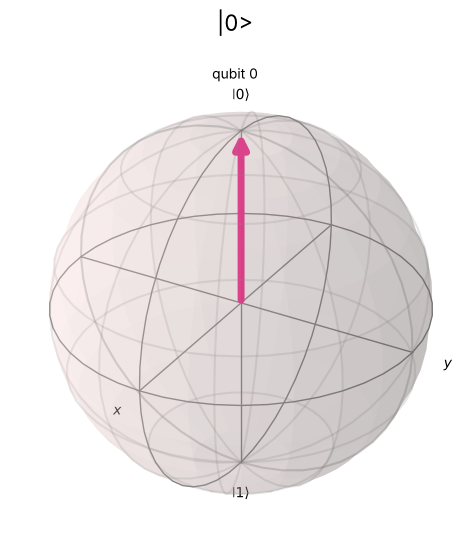

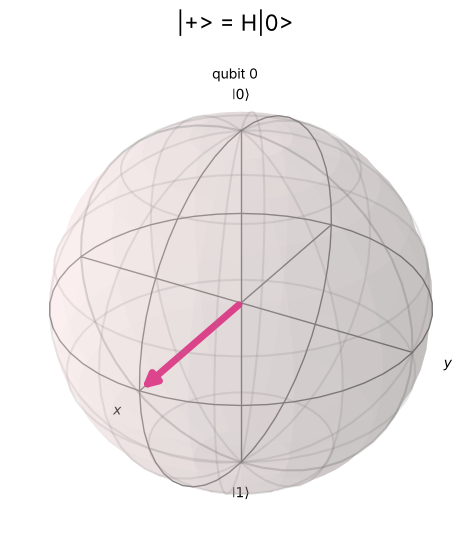

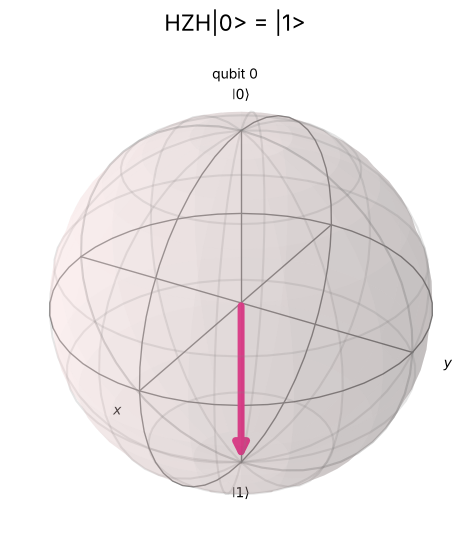

In [7]:
from qiskit.visualization import array_to_latex

H_m = Operator(HGate()).data
Z_m = Operator(ZGate()).data
X_m = Operator(XGate()).data

qc_plus = QuantumCircuit(1)
qc_plus.h(0)
plus = Statevector.from_instruction(qc_plus)
display(plus.draw("latex"))
print("H|0> = |+>:", np.allclose(plus.data, np.array([1, 1]) / np.sqrt(2)))
probabilities = plus.probabilities_dict()
print(f"p(0) = {probabilities.get('0', 0.0):.3f}, p(1) = {probabilities.get('1', 0.0):.3f}")
print("p(0) = p(1) = 1/2:", np.isclose(probabilities.get("0", 0.0), 0.5) and np.isclose(probabilities.get("1", 0.0), 0.5))

qc_hh = QuantumCircuit(1)
qc_hh.h(0)
qc_hh.h(0)
sv_hh = Statevector.from_instruction(qc_hh)
display(sv_hh.draw("latex"))
print("H^2 = I:", np.allclose(H_m @ H_m, np.eye(2)))
print("Operator(qc_hh) = I:", np.allclose(Operator(qc_hh).data, np.eye(2)))
print("H^2|0> = |0>:", sv_hh.equiv(Statevector([1, 0])))

qc_hzh = QuantumCircuit(1)
qc_hzh.h(0)
qc_hzh.z(0)
qc_hzh.h(0)
print(qc_hzh.draw())

HZH = H_m @ Z_m @ H_m
display(array_to_latex(HZH, prefix="HZH = "))
print("HZH = X (NumPy, pełne macierze):", np.allclose(HZH, X_m))
print("HZH = X (Qiskit, pełne macierze):", np.allclose(Operator(qc_hzh).data, X_m))
print("Operator(qc_hzh) == Operator(XGate()):", Operator(qc_hzh) == Operator(XGate()))

sv_hzh = Statevector.from_instruction(qc_hzh)
display(sv_hzh.draw("latex"))
print("HZH|0> = |1>:", sv_hzh.equiv(Statevector([0, 1])))

ket0 = Statevector([1, 0])
display(plot_bloch_multivector(ket0, title="|0>"))
display(plot_bloch_multivector(plus, title="|+> = H|0>"))
display(plot_bloch_multivector(sv_hzh, title="HZH|0> = |1>"))
plt.close("all")

## 🧩 Zadanie 4: Rozszerzenie na dwa kubity

Przyjmij stan $|q_0\rangle$ **przed pomiarem**, wyznaczony w punkcie 1 zadania 1, oraz $|q_1\rangle=|0\rangle$.

1. Oblicz $|\psi_{\mathrm{total}}\rangle=|q_1\rangle\otimes|q_0\rangle$ w kolejności Qiskita $|q_1q_0\rangle$.
2. Zastosuj bramkę $X$ do kubitu $q_1$.
3. Zweryfikuj oba wektory za pomocą `Statevector`. Stan początkowy zbuduj np. przez `np.kron`. Aby zastosować obwód do tego stanu, użyj `sv.evolve(qc)` — metoda `from_instruction(qc)` rozpoczyna obliczenia od stanu zerowego.


#### ✍️ Obliczenia i uzasadnienie

Z zadania 1: $|q_0\rangle=\frac{2}{\sqrt5}|0\rangle+\frac{i}{\sqrt5}|1\rangle=\frac1{\sqrt5}\begin{pmatrix}2\\ i\end{pmatrix}$, $|q_1\rangle=|0\rangle=\begin{pmatrix}1\\0\end{pmatrix}$.

Kolejność wektorów bazowych (Qiskit, $|q_1q_0\rangle$): $|00\rangle,|01\rangle,|10\rangle,|11\rangle$.

**1. Iloczyn tensorowy.**
$$|\psi_{\mathrm{total}}\rangle=|q_1\rangle\otimes|q_0\rangle=\begin{pmatrix}1\\0\end{pmatrix}\otimes\frac1{\sqrt5}\begin{pmatrix}2\\ i\end{pmatrix}=\frac1{\sqrt5}\begin{pmatrix}1\cdot2\\1\cdot i\\0\cdot2\\0\cdot i\end{pmatrix}=\frac1{\sqrt5}\begin{pmatrix}2\\ i\\0\\0\end{pmatrix}=\frac{2}{\sqrt5}|00\rangle+\frac{i}{\sqrt5}|01\rangle.$$

**2. Bramka $X$ na $q_1$.** Na całym układzie działa operator $X\otimes I$ ($q_1$ stoi po lewej):
$$X\otimes I=\begin{pmatrix}0&0&1&0\\0&0&0&1\\1&0&0&0\\0&1&0&0\end{pmatrix},\qquad (X\otimes I)|\psi_{\mathrm{total}}\rangle=\frac1{\sqrt5}\begin{pmatrix}0\\0\\2\\ i\end{pmatrix}=\frac{2}{\sqrt5}|10\rangle+\frac{i}{\sqrt5}|11\rangle.$$
Równoważnie: $(X|0\rangle)\otimes|q_0\rangle=|1\rangle\otimes|q_0\rangle$. Bramka zmienia tylko lewy bit etykiety; stan $q_0$, jego amplitudy i faza pozostają bez zmian. Prawdopodobieństwa: $p(10)=\frac45$, $p(11)=\frac15$.


In [8]:
q0 = np.array([2 / np.sqrt(5), 1j / np.sqrt(5)])
q1 = np.array([1, 0])

psi_total = Statevector(np.kron(q1, q0))
expected_total = np.array([2, 1j, 0, 0]) / np.sqrt(5)
display(psi_total.draw("latex"))
print("|q1> ⊗ |q0> zgodny z analitycznym:", np.allclose(psi_total.data, expected_total))
print("Normalizacja:", psi_total.is_valid())

qc_x1 = QuantumCircuit(2)
qc_x1.x(1)
print(qc_x1.draw())

psi_after = psi_total.evolve(qc_x1)
expected_after = np.array([0, 0, 2, 1j]) / np.sqrt(5)
display(psi_after.draw("latex"))
print("Stan po X na q1 zgodny z analitycznym:", np.allclose(psi_after.data, expected_after))

X_m = Operator(XGate()).data
X_on_q1 = np.kron(X_m, np.eye(2))
print("Operator(qc) = X ⊗ I:", np.allclose(Operator(qc_x1).data, X_on_q1))
print("(X ⊗ I)|psi> zgodne z evolve:", np.allclose(X_on_q1 @ psi_total.data, psi_after.data))
print("Wynik = (X|0>) ⊗ |q0>:", np.allclose(psi_after.data, np.kron(X_m @ q1, q0)))

probabilities = psi_after.probabilities_dict()
print(f"p(10) = {probabilities.get('10', 0.0):.3f}, p(11) = {probabilities.get('11', 0.0):.3f}")
show_probabilities(psi_after)

<IPython.core.display.Latex object>

|q1> ⊗ |q0> zgodny z analitycznym: True
Normalizacja: True
          
q_0: ─────
     ┌───┐
q_1: ┤ X ├
     └───┘


<IPython.core.display.Latex object>

Stan po X na q1 zgodny z analitycznym: True
Operator(qc) = X ⊗ I: True
(X ⊗ I)|psi> zgodne z evolve: True
Wynik = (X|0>) ⊗ |q0>: True
p(10) = 0.800, p(11) = 0.200


| Stan | Prawdopodobieństwo | Procent |
|:---:|---:|---:|
| $\vert 10\rangle$ | 0.800 | 80.0% |
| $\vert 11\rangle$ | 0.200 | 20.0% |

## 🧩 Zadanie 5: Konstrukcja stanu Bella

Wykaż, że zastosowanie $H$ do $q_0$, a następnie `CNOT(q0, q1)`, przekształca $|00\rangle$ w
$$|\Phi^+\rangle=\frac1{\sqrt2}(|00\rangle+|11\rangle).$$
Zweryfikuj rozkład prawdopodobieństwa, w tym zerowe prawdopodobieństwa stanów $|01\rangle$ i $|10\rangle$.

Przy sprawdzaniu zerowych prawdopodobieństw możesz użyć `probabilities.get("01", 0.0)` oraz `probabilities.get("10", 0.0)`, gdzie `probabilities` jest wynikiem `sv.probabilities_dict()`. Brak klucza w słowniku oznacza tutaj zerowe prawdopodobieństwo.


#### ✍️ Obliczenia i uzasadnienie

Kolejność bazy (Qiskit, $|q_1q_0\rangle$): $|00\rangle,|01\rangle,|10\rangle,|11\rangle$.

Po bramce $H$ na $q_0$:
$$(I\otimes H)|00\rangle=|0\rangle_{q_1}\otimes H|0\rangle_{q_0}=|0\rangle\otimes\frac{|0\rangle+|1\rangle}{\sqrt2}=\frac{|00\rangle+|01\rangle}{\sqrt2}=\frac1{\sqrt2}\begin{pmatrix}1\\1\\0\\0\end{pmatrix}.$$

`CNOT(q0, q1)`: jeśli $q_0=1$, neguje $q_1$. W notacji $|q_1q_0\rangle$: $|00\rangle\mapsto|00\rangle$, $|01\rangle\mapsto|11\rangle$, $|10\rangle\mapsto|10\rangle$, $|11\rangle\mapsto|01\rangle$. Z liniowości:
$$\mathrm{CNOT}\,\frac{|00\rangle+|01\rangle}{\sqrt2}=\frac{|00\rangle+|11\rangle}{\sqrt2}=|\Phi^+\rangle.$$

Macierzowo:
$$\begin{pmatrix}1&0&0&0\\0&0&0&1\\0&0&1&0\\0&1&0&0\end{pmatrix}\frac1{\sqrt2}\begin{pmatrix}1\\1\\0\\0\end{pmatrix}=\frac1{\sqrt2}\begin{pmatrix}1\\0\\0\\1\end{pmatrix}.$$

Rozkład prawdopodobieństwa:
$$p(00)=p(11)=\left(\tfrac1{\sqrt2}\right)^2=\tfrac12,\qquad p(01)=p(10)=0.$$
Wyniki obu kubitów są zawsze zgodne. Stanu nie da się zapisać jako $|a\rangle\otimes|b\rangle$: wymagałoby to $a_0b_0\neq0$ i $a_1b_1\neq0$ przy $a_0b_1=0$ lub $a_1b_0=0$, co jest sprzeczne — stan jest splątany.


In [9]:
from qiskit.visualization import array_to_latex

qc_bell = QuantumCircuit(2)
qc_bell.h(0)
qc_bell.cx(0, 1)
print(qc_bell.draw())

qc_h0 = QuantumCircuit(2)
qc_h0.h(0)
sv_h0 = Statevector.from_instruction(qc_h0)
display(sv_h0.draw("latex"))
print("Po H na q0 = (|00> + |01>)/sqrt(2):", np.allclose(sv_h0.data, np.array([1, 1, 0, 0]) / np.sqrt(2)))

sv_bell = Statevector.from_instruction(qc_bell)
phi_plus = Statevector(np.array([1, 0, 0, 1]) / np.sqrt(2))
display(sv_bell.draw("latex"))
print("Stan końcowy = |Phi+>:", np.allclose(sv_bell.data, phi_plus.data))
print("equiv:", sv_bell.equiv(phi_plus))

CNOT_little = np.array([[1, 0, 0, 0],
                        [0, 0, 0, 1],
                        [0, 0, 1, 0],
                        [0, 1, 0, 0]])
H_m = Operator(HGate()).data
U_bell = CNOT_little @ np.kron(np.eye(2), H_m)
display(array_to_latex(Operator(qc_bell).data, prefix="U = "))
print("Operator(qc) = CNOT (I ⊗ H):", np.allclose(Operator(qc_bell).data, U_bell))

probabilities = sv_bell.probabilities_dict()
show_probabilities(sv_bell)
p00 = probabilities.get("00", 0.0)
p01 = probabilities.get("01", 0.0)
p10 = probabilities.get("10", 0.0)
p11 = probabilities.get("11", 0.0)
print(f"p(00) = {p00:.3f}, p(01) = {p01:.3f}, p(10) = {p10:.3f}, p(11) = {p11:.3f}")
print("p(00) = p(11) = 1/2:", np.isclose(p00, 0.5) and np.isclose(p11, 0.5))
print("p(01) = p(10) = 0:", np.isclose(p01, 0.0) and np.isclose(p10, 0.0))

     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘


<IPython.core.display.Latex object>

Po H na q0 = (|00> + |01>)/sqrt(2): True


<IPython.core.display.Latex object>

Stan końcowy = |Phi+>: True
equiv: True


<IPython.core.display.Latex object>

Operator(qc) = CNOT (I ⊗ H): True


| Stan | Prawdopodobieństwo | Procent |
|:---:|---:|---:|
| $\vert 00\rangle$ | 0.500 | 50.0% |
| $\vert 11\rangle$ | 0.500 | 50.0% |

p(00) = 0.500, p(01) = 0.000, p(10) = 0.000, p(11) = 0.500
p(00) = p(11) = 1/2: True
p(01) = p(10) = 0: True


## 🧩 Zadanie 6: Wpływ fazy na stan kwantowy

Dla $|+\rangle=\frac1{\sqrt2}(|0\rangle+|1\rangle)$:

1. Oblicz $Z|+\rangle$ i sprawdź $p(1)$.
2. Oblicz $S|+\rangle$.
3. Narysuj na sferze Blocha stany $|+\rangle$, $Z|+\rangle$ oraz $S|+\rangle$. Porównaj kierunki wektorów Blocha i zinterpretuj wpływ fazy względnej.


#### ✍️ Obliczenia i uzasadnienie

**1. Bramka $Z$.**
$$Z|+\rangle=\begin{pmatrix}1&0\\0&-1\end{pmatrix}\frac1{\sqrt2}\begin{pmatrix}1\\1\end{pmatrix}=\frac1{\sqrt2}\begin{pmatrix}1\\-1\end{pmatrix}=|-\rangle,\qquad p(1)=\left|-\tfrac1{\sqrt2}\right|^2=\tfrac12.$$
Prawdopodobieństwo $p(1)$ jest takie samo jak dla $|+\rangle$.

**2. Bramka $S$.**
$$S|+\rangle=\begin{pmatrix}1&0\\0&i\end{pmatrix}\frac1{\sqrt2}\begin{pmatrix}1\\1\end{pmatrix}=\frac1{\sqrt2}\begin{pmatrix}1\\ i\end{pmatrix}=\frac{|0\rangle+i|1\rangle}{\sqrt2}=|{+i}\rangle,\qquad p(0)=p(1)=\tfrac12.$$

**3. Sfera Blocha.** Dla stanu $\frac1{\sqrt2}(|0\rangle+e^{i\varphi}|1\rangle)$ wektor Blocha to $(\cos\varphi,\sin\varphi,0)$:
- $|+\rangle$, $\varphi=0$: $(1,0,0)$ — dodatnia oś $x$;
- $Z|+\rangle=|-\rangle$, $\varphi=\pi$: $(-1,0,0)$ — ujemna oś $x$;
- $S|+\rangle=|{+i}\rangle$, $\varphi=\frac\pi2$: $(0,1,0)$ — dodatnia oś $y$.

Wszystkie trzy wektory leżą na równiku ($r_z=0$), dlatego pomiar w bazie obliczeniowej daje zawsze $p(0)=p(1)=\frac12$. Faza względna $\varphi$ to kąt azymutalny: $Z$ obraca wektor o $\pi$, a $S$ o $\frac\pi2$ wokół osi $z$. Stany są fizycznie różne ($|+\rangle$ i $|-\rangle$ są ortogonalne, a $|{+i}\rangle$ jest od nich różny), co ujawnia pomiar w innej bazie — np. po $H$: $H|+\rangle=|0\rangle$, $H|-\rangle=|1\rangle$, natomiast $H|{+i}\rangle$ daje $p(0)=p(1)=\frac12$.


<IPython.core.display.Latex object>

Z|+> = |->: True
p(1) dla |+>: 0.500, dla Z|+>: 0.500, równe 1/2: True


<IPython.core.display.Latex object>

S|+> = (|0> + i|1>)/sqrt(2): True
p(1) dla S|+>: 0.500
Z|+> równoważny |+>: False
S|+> równoważny |+>: False
Wektor Blocha |+>: [1. 0. 0.], zgodny z [1, 0, 0]: True
Wektor Blocha Z|+>: [-1.  0.  0.], zgodny z [-1, 0, 0]: True
Wektor Blocha S|+>: [0. 1. 0.], zgodny z [0, 1, 0]: True
Pomiar po H dla |+>: p(0) = 1.000, p(1) = 0.000
Pomiar po H dla Z|+>: p(0) = 0.000, p(1) = 1.000
Pomiar po H dla S|+>: p(0) = 0.500, p(1) = 0.500


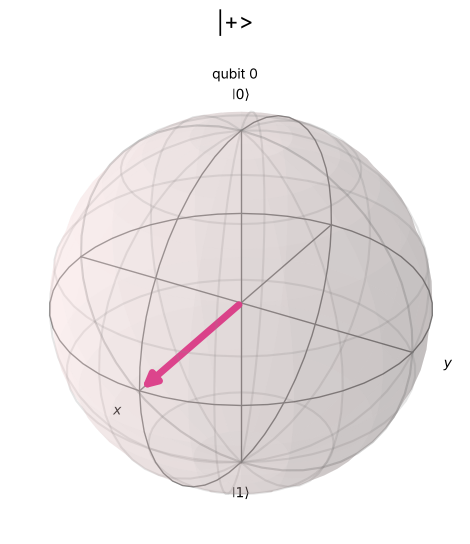

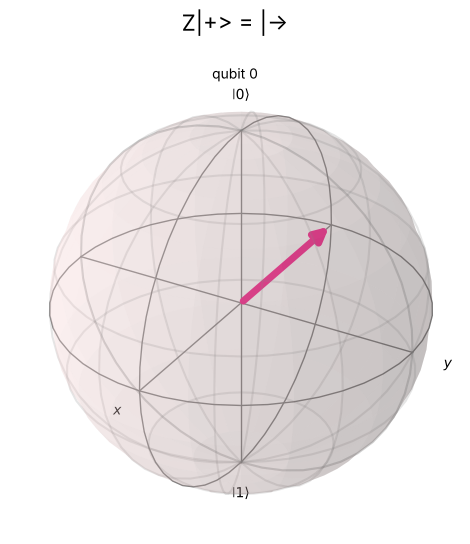

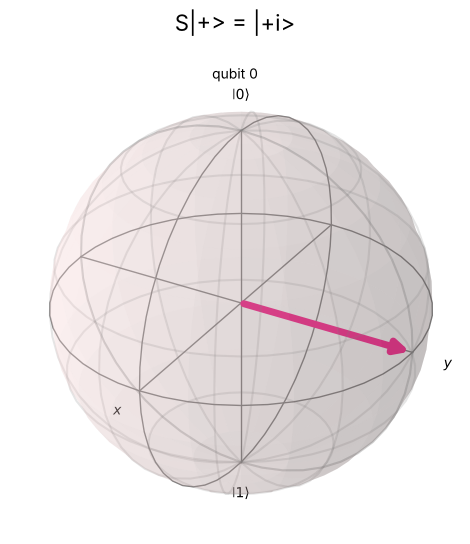

In [10]:
plus = Statevector([1 / np.sqrt(2), 1 / np.sqrt(2)])

qc_z = QuantumCircuit(1)
qc_z.z(0)
z_plus = plus.evolve(qc_z)
display(z_plus.draw("latex"))
print("Z|+> = |->:", np.allclose(z_plus.data, np.array([1, -1]) / np.sqrt(2)))
p1_z = z_plus.probabilities_dict().get("1", 0.0)
p1_plus = plus.probabilities_dict().get("1", 0.0)
print(f"p(1) dla |+>: {p1_plus:.3f}, dla Z|+>: {p1_z:.3f}, równe 1/2: {np.isclose(p1_z, 0.5)}")

qc_s = QuantumCircuit(1)
qc_s.s(0)
s_plus = plus.evolve(qc_s)
display(s_plus.draw("latex"))
print("S|+> = (|0> + i|1>)/sqrt(2):", np.allclose(s_plus.data, np.array([1, 1j]) / np.sqrt(2)))
print(f"p(1) dla S|+>: {s_plus.probabilities_dict().get('1', 0.0):.3f}")

print("Z|+> równoważny |+>:", z_plus.equiv(plus))
print("S|+> równoważny |+>:", s_plus.equiv(plus))

pauli_x = Operator(XGate()).data
pauli_y = Operator(YGate()).data
pauli_z = Operator(ZGate()).data
for name, state, expected in [("|+>", plus, [1, 0, 0]), ("Z|+>", z_plus, [-1, 0, 0]), ("S|+>", s_plus, [0, 1, 0])]:
    v = state.data
    bloch = np.real([v.conj() @ pauli_x @ v, v.conj() @ pauli_y @ v, v.conj() @ pauli_z @ v])
    print(f"Wektor Blocha {name}: {np.round(bloch, 6) + 0.0}, zgodny z {expected}: {np.allclose(bloch, expected)}")

qc_h = QuantumCircuit(1)
qc_h.h(0)
for name, state in [("|+>", plus), ("Z|+>", z_plus), ("S|+>", s_plus)]:
    probs = state.evolve(qc_h).probabilities()
    print(f"Pomiar po H dla {name}: p(0) = {probs[0]:.3f}, p(1) = {probs[1]:.3f}")

display(plot_bloch_multivector(plus, title="|+>"))
display(plot_bloch_multivector(z_plus, title="Z|+> = |->"))
display(plot_bloch_multivector(s_plus, title="S|+> = |+i>"))
plt.close("all")

## 🧩 Zadanie 7: Weryfikacja unitarności bramek kwantowych

1. Sprawdź analitycznie unitarność bramek $H$ i $S$.
2. Zweryfikuj w Qiskicie bramki $H,X,Y,Z,S,T$.
3. Rozważ nieunitarną macierz
$$A=\begin{pmatrix}1&1\\1&1\end{pmatrix}.$$
Oblicz normy wektorów $A|+\rangle$ i $A|-\rangle$ oraz porównaj je z normami stanów wejściowych. Wyjaśnij, dlaczego $A$ nie zachowuje normy dla wszystkich stanów i nie może reprezentować deterministycznej bramki unitarnej. W tej części nie normalizuj automatycznie wyników mnożenia; normę oblicz np. przez `np.linalg.norm`.


#### ✍️ Obliczenia i uzasadnienie

**1. Unitarność $H$ i $S$.** Macierz jest unitarna, gdy $U^\dagger U=I$.

$H=\frac1{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ jest rzeczywista i symetryczna, więc $H^\dagger=H$:
$$H^\dagger H=\frac12\begin{pmatrix}1&1\\1&-1\end{pmatrix}\begin{pmatrix}1&1\\1&-1\end{pmatrix}=\frac12\begin{pmatrix}2&0\\0&2\end{pmatrix}=I.$$

$S=\begin{pmatrix}1&0\\0&i\end{pmatrix}$, $S^\dagger=\begin{pmatrix}1&0\\0&-i\end{pmatrix}$:
$$S^\dagger S=\begin{pmatrix}1&0\\0&(-i)\,i\end{pmatrix}=\begin{pmatrix}1&0\\0&1\end{pmatrix}=I.$$

**2.** Bramki $H,X,Y,Z,S,T$ sprawdzamy w Qiskicie warunkiem $U^\dagger U=I$ oraz metodą `is_unitary()`.

**3. Macierz $A=\begin{pmatrix}1&1\\1&1\end{pmatrix}$.**
$$A|+\rangle=\frac1{\sqrt2}\begin{pmatrix}1&1\\1&1\end{pmatrix}\begin{pmatrix}1\\1\end{pmatrix}=\frac1{\sqrt2}\begin{pmatrix}2\\2\end{pmatrix}=\begin{pmatrix}\sqrt2\\\sqrt2\end{pmatrix},\qquad \|A|+\rangle\|=\sqrt{2+2}=2,$$
$$A|-\rangle=\frac1{\sqrt2}\begin{pmatrix}1&1\\1&1\end{pmatrix}\begin{pmatrix}1\\-1\end{pmatrix}=\begin{pmatrix}0\\0\end{pmatrix},\qquad \|A|-\rangle\|=0.$$
Normy wejść: $\||+\rangle\|=\||-\rangle\|=1$. Wynik $A|+\rangle$ ma normę $2$ (sumaryczne „prawdopodobieństwo” $4$), a $A|-\rangle$ jest wektorem zerowym, który nie opisuje żadnego stanu.

Przyczyna:
$$A^\dagger A=A^2=\begin{pmatrix}2&2\\2&2\end{pmatrix}=2A\neq I,\qquad \det A=0.$$
$A=2|+\rangle\langle+|$ ma wartości własne $2$ (wektor $|+\rangle$) i $0$ (wektor $|-\rangle$), a zachowanie normy wymaga, by wszystkie wartości własne miały moduł $1$. Ponieważ $\det A=0$, macierz jest nieodwracalna — informacja o składowej $|-\rangle$ zostaje bezpowrotnie utracona. Ewolucja zamkniętego układu kwantowego musi zachowywać normę (sumę prawdopodobieństw równą $1$) i być odwracalna, czyli unitarna, więc $A$ nie może reprezentować deterministycznej bramki kwantowej.


In [11]:
from qiskit.visualization import array_to_latex

I2 = np.eye(2)

H_m = Operator(HGate()).data
S_m = Operator(SGate()).data
print("H zgodna z analityczną:", np.allclose(H_m, np.array([[1, 1], [1, -1]]) / np.sqrt(2)))
print("S zgodna z analityczną:", np.allclose(S_m, np.array([[1, 0], [0, 1j]])))
display(array_to_latex(H_m.conj().T @ H_m, prefix="H^\\dagger H = "))
display(array_to_latex(S_m.conj().T @ S_m, prefix="S^\\dagger S = "))

gates = {"H": HGate(), "X": XGate(), "Y": YGate(), "Z": ZGate(), "S": SGate(), "T": TGate()}
for name, gate in gates.items():
    op = Operator(gate)
    U = op.data
    print(f"{name}: U†U = I: {np.allclose(U.conj().T @ U, I2)}, UU† = I: {np.allclose(U @ U.conj().T, I2)}, is_unitary(): {op.is_unitary()}")

A = np.array([[1, 1], [1, 1]])
ket_plus = np.array([1, 1]) / np.sqrt(2)
ket_minus = np.array([1, -1]) / np.sqrt(2)

A_plus = A @ ket_plus
A_minus = A @ ket_minus
print("A|+> =", A_plus)
print("A|-> =", A_minus)
print(f"norma |+> = {np.linalg.norm(ket_plus):.6f}, norma A|+> = {np.linalg.norm(A_plus):.6f}, zgodność z 2: {np.isclose(np.linalg.norm(A_plus), 2)}")
print(f"norma |-> = {np.linalg.norm(ket_minus):.6f}, norma A|-> = {np.linalg.norm(A_minus):.6f}, zgodność z 0: {np.isclose(np.linalg.norm(A_minus), 0)}")

print("A†A = I:", np.allclose(A.conj().T @ A, I2))
display(array_to_latex(A.conj().T @ A, prefix="A^\\dagger A = "))
print("det A =", np.linalg.det(A))
print("Wartości własne A:", np.linalg.eigvals(A))
print("Operator(A).is_unitary():", Operator(A).is_unitary())

H zgodna z analityczną: True
S zgodna z analityczną: True


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

H: U†U = I: True, UU† = I: True, is_unitary(): True
X: U†U = I: True, UU† = I: True, is_unitary(): True
Y: U†U = I: True, UU† = I: True, is_unitary(): True
Z: U†U = I: True, UU† = I: True, is_unitary(): True
S: U†U = I: True, UU† = I: True, is_unitary(): True
T: U†U = I: True, UU† = I: True, is_unitary(): True
A|+> = [1.41421356 1.41421356]
A|-> = [0. 0.]
norma |+> = 1.000000, norma A|+> = 2.000000, zgodność z 2: True
norma |-> = 1.000000, norma A|-> = 0.000000, zgodność z 0: True
A†A = I: False


<IPython.core.display.Latex object>

det A = 0.0
Wartości własne A: [2.+0.j 0.+0.j]
Operator(A).is_unitary(): False


## 🧩 Zadanie 8: Weryfikacja bramki CNOT

W konwencji Qiskita stan zapisujemy jako $|q_1q_0\rangle$, a `cx(0, 1)` ma $q_0$ jako sterowanie i $q_1$ jako cel.

1. Rozwiń
$$I\otimes|0\rangle\!\langle0|+X\otimes|1\rangle\!\langle1|.$$
2. Zweryfikuj macierz w NumPy i Qiskicie. Jawnie podaj uporządkowaną bazę, w której zapisujesz macierz.
3. Podaj macierz w bazie zapisanej jako $|q_0q_1\rangle$, w której $q_0$ jest najbardziej znaczącym bitem (zapis big-endian). Zachowaj te same role: $q_0$ steruje, a $q_1$ jest celem. Wypisz kolejność czterech wektorów bazowych i wyjaśnij, dlaczego zmiana reprezentacji macierzowej nie oznacza zmiany operacji fizycznej.


#### ✍️ Obliczenia i uzasadnienie

Oznaczenia: $|0\rangle\!\langle0|=\begin{pmatrix}1&0\\0&0\end{pmatrix}$, $|1\rangle\!\langle1|=\begin{pmatrix}0&0\\0&1\end{pmatrix}$.

**1–2. Kolejność Qiskita $|q_1q_0\rangle$**, baza uporządkowana: $|00\rangle,|01\rangle,|10\rangle,|11\rangle$ (indeksy $0,1,2,3$, $q_0$ — najmniej znaczący bit).

Dla kolejności $|q_1q_0\rangle$ operator sterowany przez prawy kubit ma postać
$$CNOT_{\mathrm{little}}=I\otimes|0\rangle\!\langle0|+X\otimes|1\rangle\!\langle1|,$$
$$I\otimes|0\rangle\!\langle0|=\begin{pmatrix}1&0&0&0\\0&0&0&0\\0&0&1&0\\0&0&0&0\end{pmatrix},\qquad X\otimes|1\rangle\!\langle1|=\begin{pmatrix}0&0&0&0\\0&0&0&1\\0&0&0&0\\0&1&0&0\end{pmatrix},$$
$$CNOT_{\mathrm{little}}=\begin{pmatrix}1&0&0&0\\0&0&0&1\\0&0&1&0\\0&1&0&0\end{pmatrix}.$$
Działanie: $|00\rangle\mapsto|00\rangle$, $|01\rangle\mapsto|11\rangle$, $|10\rangle\mapsto|10\rangle$, $|11\rangle\mapsto|01\rangle$ — gdy $q_0=1$, zmienia się $q_1$.

**3. Kolejność big-endian $|q_0q_1\rangle$**, baza uporządkowana: $|00\rangle,|01\rangle,|10\rangle,|11\rangle$, gdzie teraz lewy bit to $q_0$ (najbardziej znaczący).

Przy kolejności big-endian $|q_0q_1\rangle$ projektor kubitu sterującego znajduje się po lewej stronie iloczynu tensorowego:
$$CNOT_{\mathrm{big}}=|0\rangle\!\langle0|\otimes I+|1\rangle\!\langle1|\otimes X=\begin{pmatrix}1&0&0&0\\0&1&0&0\\0&0&0&1\\0&0&1&0\end{pmatrix}.$$
Działanie: $|00\rangle\mapsto|00\rangle$, $|01\rangle\mapsto|01\rangle$, $|10\rangle\mapsto|11\rangle$, $|11\rangle\mapsto|10\rangle$.

Obie macierze opisują tę samą relację sterowanie-cel, ale w różnych uporządkowaniach wektorów bazowych. Przejście między kolejnościami to permutacja bazy $P=\mathrm{SWAP}$ (zamienia wektory $|01\rangle\leftrightarrow|10\rangle$, $P=P^{-1}$):
$$CNOT_{\mathrm{big}}=P\,CNOT_{\mathrm{little}}\,P.$$
Jest to zmiana reprezentacji (zmiana nazw i kolejności wektorów bazowych), a nie zmiana operacji: w obu zapisach dokładnie ten sam stan fizyczny „$q_0=1,\ q_1=0$” (etykieta $|01\rangle$ w little-endian, $|10\rangle$ w big-endian) przechodzi w „$q_0=1,\ q_1=1$” (etykieta $|11\rangle$ w obu), a stany z $q_0=0$ nie zmieniają się. Wszystkie amplitudy i prawdopodobieństwa przypisane konkretnym wartościom $q_0,q_1$ są takie same.


In [12]:
from qiskit.visualization import array_to_latex

I2 = np.eye(2)
X_m = Operator(XGate()).data
P0 = np.array([[1, 0], [0, 0]])
P1 = np.array([[0, 0], [0, 1]])

CNOT_little = np.kron(I2, P0) + np.kron(X_m, P1)
CNOT_little_expected = np.array([[1, 0, 0, 0],
                                 [0, 0, 0, 1],
                                 [0, 0, 1, 0],
                                 [0, 1, 0, 0]])
print("Baza little-endian |q1 q0>: |00>, |01>, |10>, |11>")
display(array_to_latex(CNOT_little, prefix="CNOT_{little} = "))
print("NumPy = macierz analityczna:", np.allclose(CNOT_little, CNOT_little_expected))

qc_cx = QuantumCircuit(2)
qc_cx.cx(0, 1)
print(qc_cx.draw())
CNOT_qiskit = Operator(qc_cx).data
print("Operator(cx(0, 1)) = CNOT_little:", np.allclose(CNOT_qiskit, CNOT_little))
print("CNOT_little unitarna:", Operator(CNOT_little).is_unitary())

for label in ["00", "01", "10", "11"]:
    out = Statevector.from_label(label).evolve(qc_cx)
    print(f"|{label}> -> |{list(out.probabilities_dict())[0]}>")

CNOT_big = np.kron(P0, I2) + np.kron(P1, X_m)
CNOT_big_expected = np.array([[1, 0, 0, 0],
                              [0, 1, 0, 0],
                              [0, 0, 0, 1],
                              [0, 0, 1, 0]])
print("Baza big-endian |q0 q1>: |00>, |01>, |10>, |11>")
display(array_to_latex(CNOT_big, prefix="CNOT_{big} = "))
print("NumPy = macierz analityczna:", np.allclose(CNOT_big, CNOT_big_expected))
print("Operator(cx(0, 1)).reverse_qargs() = CNOT_big:", np.allclose(Operator(qc_cx).reverse_qargs().data, CNOT_big))

SWAP = np.array([[1, 0, 0, 0],
                 [0, 0, 1, 0],
                 [0, 1, 0, 0],
                 [0, 0, 0, 1]])
print("CNOT_big = SWAP · CNOT_little · SWAP:", np.allclose(CNOT_big, SWAP @ CNOT_little @ SWAP))
print("CNOT_little == CNOT_big:", np.allclose(CNOT_little, CNOT_big))

rng = np.random.default_rng(0)
q0 = rng.normal(size=2) + 1j * rng.normal(size=2)
q0 /= np.linalg.norm(q0)
q1 = rng.normal(size=2) + 1j * rng.normal(size=2)
q1 /= np.linalg.norm(q1)
out_little = (CNOT_little @ np.kron(q1, q0)).reshape(2, 2)
out_big = (CNOT_big @ np.kron(q0, q1)).reshape(2, 2)
print("Ta sama operacja fizyczna (amplitudy a[q0, q1] równe):", np.allclose(out_little.T, out_big))

Baza little-endian |q1 q0>: |00>, |01>, |10>, |11>


<IPython.core.display.Latex object>

NumPy = macierz analityczna: True
          
q_0: ──■──
     ┌─┴─┐
q_1: ┤ X ├
     └───┘
Operator(cx(0, 1)) = CNOT_little: True
CNOT_little unitarna: True
|00> -> |00>
|01> -> |11>
|10> -> |10>
|11> -> |01>
Baza big-endian |q0 q1>: |00>, |01>, |10>, |11>


<IPython.core.display.Latex object>

NumPy = macierz analityczna: True
Operator(cx(0, 1)).reverse_qargs() = CNOT_big: True
CNOT_big = SWAP · CNOT_little · SWAP: True
CNOT_little == CNOT_big: False
Ta sama operacja fizyczna (amplitudy a[q0, q1] równe): True
